# Customer Churn Predictor: ANN Training Notebook
End-to-end pipeline: load, clean, split, preprocess, build, train, evaluate, save. The trained artifacts are consumed by `app.py`.

## Step 0: Setup

In [1]:
import os, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')
import tensorflow as tf
print('TensorFlow version:', tf.__version__)
print('CSV present:', os.path.exists('data/Churn_Modelling.csv'))

I0000 00:00:1794578008.977462     151 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794578010.102508     151 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
CSV present: True


**My understanding:** TensorFlow/Keras builds and trains the neural network, pandas holds and cleans the table of customers, and scikit-learn handles splitting, encoding, scaling and the evaluation metrics. joblib saves the fitted preprocessor to disk, matplotlib draws the loss curve, and Streamlit turns the saved model into a web app. Checking the TensorFlow version and the CSV now avoids confusing errors later.

## Step 1: Load the data

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)

df = pd.read_csv('data/Churn_Modelling.csv')
print('Shape:', df.shape)
df.head()

Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**My understanding:** A DataFrame is a table in memory where each row is one bank customer and each column is one property of that customer, such as age, balance or country. The shape (10000, 14) confirms all customers and columns loaded. I fixed the random seeds so that the split and the training give the same results every time I rerun the notebook.

## Step 2: Explore and clean

In [3]:
df.info()
print('\nMissing values in total:', df.isnull().sum().sum())
print('\nClass counts (0 = stayed, 1 = left):')
print(df['Exited'].value_counts())
print('\nChurn rate: %.2f%%' % (df['Exited'].mean() * 100))
print('Always-predict-stay baseline accuracy: %.2f%%' % ((1 - df['Exited'].mean()) * 100))

df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
print('\nShape after dropping ID columns:', df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB

Missing values in total: 0

Class counts (0 = stayed, 1 = left):
Exited
0    7963
1    2037
Name: count, dty

**My understanding:** RowNumber, CustomerId and Surname only identify a person and carry no behavioural signal, so keeping them would add noise and could let the model memorise individuals. About 80% of customers stayed and 20% left, which means a model that always says "stays" already reaches about 80% accuracy. My ANN has to beat that, and accuracy alone will not be enough to judge it.

## Step 3: Split into X, y, train and test

In [4]:
X = df.drop(columns=['Exited'])
y = df['Exited']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Churn rate train: %.3f  test: %.3f' % (y_train.mean(), y_test.mean()))

Train: (8000, 10)  Test: (2000, 10)
Churn rate train: 0.204  test: 0.203


**My understanding:** The test set acts as an exam the model has never seen, so its score estimates how the model behaves on real new customers instead of rewarding memorisation. `stratify=y` keeps the 20% churn share identical in both parts, which matters because churners are the minority and a random split could under-represent them. The `random_state` makes the split reproducible.

## Step 4: Preprocess (One-Hot Encoding + StandardScaler)

In [5]:
cat_cols = ['Geography', 'Gender']
num_cols = [c for c in X.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])

X_train_p = preprocessor.fit_transform(X_train)   # fit on TRAIN only
X_test_p = preprocessor.transform(X_test)         # transform only on TEST
print('Numeric columns (%d):' % len(num_cols), num_cols)
print('Processed train shape:', X_train_p.shape)
print('Processed test shape :', X_test_p.shape)

Numeric columns (8): ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Processed train shape: (8000, 13)
Processed test shape : (2000, 13)


**My understanding:** A neural network only works with numbers, so One-Hot Encoding turns Geography and Gender into separate 0/1 columns, and StandardScaler puts numeric features like Balance and Tenure on a comparable scale so large values do not dominate learning. The preprocessor is fitted on the training data only, because fitting it on the test data would leak information about the unseen set and make the evaluation too optimistic. The result is 13 columns: 8 numeric, 3 Geography and 2 Gender.

## Step 5: Build the ANN

In [6]:
n_features = X_train_p.shape[1]

def build_model(dropout=0.0):
    m = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(16, activation='relu'),
        *([layers.Dropout(dropout)] if dropout else []),
        layers.Dense(8, activation='relu'),
        *([layers.Dropout(dropout)] if dropout else []),
        layers.Dense(1, activation='sigmoid'),
    ])
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return m

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

**My understanding:** ReLU keeps positive values and zeroes out negatives, which lets the hidden layers learn non-linear patterns, while Sigmoid squashes the final value into a probability between 0 and 1. The output layer has exactly one neuron because this is a binary question and a single probability of churn is enough. Adam optimises the weights and binary cross-entropy is the matching loss for a 0/1 target.

## Step 6: Train the model

In [7]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train_p, y_train.values,
    epochs=50, batch_size=32, validation_split=0.2,
    callbacks=[early_stop], verbose=2)
print('Stopped after', len(history.history['loss']), 'epochs')

Epoch 1/50


200/200 - 1s - 5ms/step - accuracy: 0.7633 - loss: 0.5249 - val_accuracy: 0.8000 - val_loss: 0.4610


Epoch 2/50


200/200 - 1s - 3ms/step - accuracy: 0.7956 - loss: 0.4472 - val_accuracy: 0.8050 - val_loss: 0.4365


Epoch 3/50


200/200 - 1s - 3ms/step - accuracy: 0.8078 - loss: 0.4233 - val_accuracy: 0.8275 - val_loss: 0.4149


... (47 outputs left out)

200/200 - 0s - 2ms/step - accuracy: 0.8605 - loss: 0.3369 - val_accuracy: 0.8650 - val_loss: 0.3357


Epoch 28/50


200/200 - 1s - 3ms/step - accuracy: 0.8611 - loss: 0.3366 - val_accuracy: 0.8650 - val_loss: 0.3358


Stopped after 28 epochs


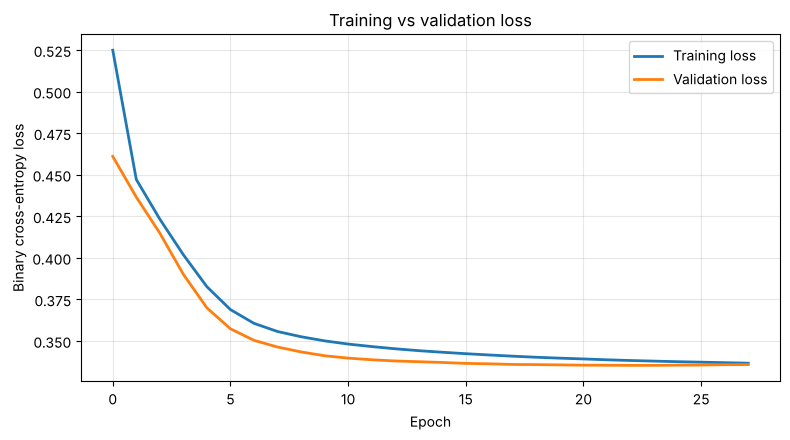

In [8]:
plt.figure(figsize=(8, 4.5))
plt.plot(history.history['loss'], label='Training loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation loss', linewidth=2)
plt.xlabel('Epoch'); plt.ylabel('Binary cross-entropy loss')
plt.title('Training vs validation loss')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('assets/loss_curve.png', dpi=150)
plt.show()

**My understanding:** An epoch is one full pass over the training data, and a batch is the small group of 32 rows the model sees before it updates its weights once. Both loss curves falling together shows the model is learning, and if the validation loss started rising while the training loss kept falling that would signal overfitting. EarlyStopping stops training at that point and restores the best weights.

## Step 7: Evaluate on the test set

Test accuracy: 0.8615

Confusion matrix:
 [[1522   71]
 [ 206  201]]

Classification report:
               precision    recall  f1-score   support

      Stayed       0.88      0.96      0.92      1593
        Left       0.74      0.49      0.59       407

    accuracy                           0.86      2000
   macro avg       0.81      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



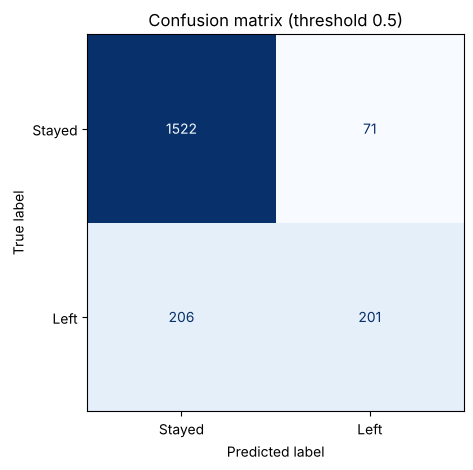

In [9]:
y_prob = model.predict(X_test_p, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print('Test accuracy: %.4f' % acc)
print('\nConfusion matrix:\n', cm)
print('\nClassification report:\n', classification_report(y_test, y_pred, target_names=['Stayed', 'Left']))

disp = ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Left'])
disp.plot(cmap='Blues', colorbar=False)
plt.title('Confusion matrix (threshold 0.5)'); plt.tight_layout()
plt.savefig('assets/confusion_matrix.png', dpi=150)
plt.show()

**My understanding:** The confusion matrix counts correct and wrong predictions per class: the top row shows customers who stayed (mostly predicted correctly), and the bottom row shows customers who left, of which the model misses a large share. Recall for class 1 is low because churners are only 20% of the data, so the model learns to be cautious about predicting a departure. A bank cares because every missed churner is a customer lost without any chance to run a retention offer.

## Step 8: Save the model and the preprocessor

In [10]:
model.save('models/model.keras')
joblib.dump(preprocessor, 'models/preprocessor.pkl')

# Sanity check on one test customer using the saved files
m2 = keras.models.load_model('models/model.keras')
p2 = joblib.load('models/preprocessor.pkl')
row = X_test.iloc[[0]]
prob = float(m2.predict(p2.transform(row), verbose=0)[0][0])
print(row.to_string(index=False))
print('\nPredicted churn probability: %.4f' % prob)
print('Predicted label:', int(prob >= 0.5), '| Actual label:', int(y_test.iloc[0]))

 CreditScore Geography Gender  Age  Tenure  Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary
         585    France   Male   36       7      0.0              2          1               0         94283.09

Predicted churn probability: 0.0277
Predicted label: 0 | Actual label: 0


**My understanding:** The preprocessor stores the exact category list and the mean and standard deviation learned from the training data. Without it, the app would feed raw text and unscaled numbers to a model that expects 13 scaled columns, producing an error or meaningless predictions. Saving both files and reloading them for a sanity check proves they work as a pair.

## Step 9: Streamlit app

The app is in `app.py`. Run it from the project root:

```
streamlit run app.py
```
The two test customers from the manual are verified below using the same code path as the app.

In [11]:
import sys; sys.path.insert(0, '.')
from app_utils import predict_proba

stay_case = dict(CreditScore=650, Geography='France', Gender='Male', Age=38, Tenure=5,
                 Balance=76000, NumOfProducts=2, HasCrCard=1, IsActiveMember=1, EstimatedSalary=100000)
leave_case = dict(CreditScore=650, Geography='Germany', Gender='Female', Age=60, Tenure=5,
                  Balance=120000, NumOfProducts=1, HasCrCard=1, IsActiveMember=0, EstimatedSalary=100000)
for name, c in [('Customer 1', stay_case), ('Customer 2', leave_case)]:
    p = predict_proba(c)
    print('%s: churn probability %.1f%% -> %s' % (name, p * 100, 'LEAVE' if p >= 0.5 else 'STAY'))

Customer 1: churn probability 1.8% -> STAY


Customer 2: churn probability 84.6% -> LEAVE


**My understanding:** When the user clicks Predict, the app collects every input widget value, converts Yes/No to 1/0, and builds a one-row DataFrame with the exact training column names. That row goes through the saved preprocessor to become 13 scaled numbers, the loaded model returns a churn probability, and the app compares it with the threshold to show a percentage and a STAY or LEAVE verdict. The model and preprocessor are loaded once at start-up and cached.

## Bonus challenges

In [12]:
def evaluate(m, name, class_weight=None):
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    m.fit(X_train_p, y_train.values, epochs=50, batch_size=32, validation_split=0.2,
          callbacks=[stop], class_weight=class_weight, verbose=0)
    pr = (m.predict(X_test_p, verbose=0).ravel() >= 0.5).astype(int)
    rep = classification_report(y_test, pr, output_dict=True)
    return dict(Model=name, Accuracy=round(accuracy_score(y_test, pr), 4),
                Recall_Class1=round(rep['1']['recall'], 3), Precision_Class1=round(rep['1']['precision'], 3))

base_rep = classification_report(y_test, y_pred, output_dict=True)
rows = [dict(Model='Baseline', Accuracy=round(acc, 4),
             Recall_Class1=round(base_rep['1']['recall'], 3),
             Precision_Class1=round(base_rep['1']['precision'], 3))]
keras.utils.set_random_seed(SEED)
rows.append(evaluate(build_model(dropout=0.2), 'Dropout 0.2'))
keras.utils.set_random_seed(SEED)
rows.append(evaluate(build_model(), 'class_weight {0:1, 1:3}', class_weight={0: 1, 1: 3}))
pd.DataFrame(rows)

,Model,Accuracy,Recall_Class1,Precision_Class1
0,Baseline,0.8615,0.494,0.739
1,Dropout 0.2,0.8655,0.457,0.795
2,"class_weight {0:1, 1:3}",0.8175,0.713,0.539


**My understanding (bonus):** Dropout randomly switches off neurons during training and mainly acts as a safeguard against overfitting, so the accuracy change is small on a network this size. Giving class 1 triple weight makes the model pay more for missing churners, so class-1 recall rises while accuracy and precision drop. A bank would usually prefer the higher recall, since a wasted retention offer costs far less than a lost customer. The app also includes a 0.3 to 0.7 decision-threshold slider.

## Final summary

In [13]:
rep = classification_report(y_test, y_pred, output_dict=True)
print('Test accuracy      : %.2f%%' % (acc * 100))
print('Class-1 recall     : %.3f' % rep['1']['recall'])
print('Class-1 precision  : %.3f' % rep['1']['precision'])

Test accuracy      : 86.15%
Class-1 recall     : 0.494
Class-1 precision  : 0.739


**Summary:** The ANN beats the 80% always-stay baseline, with the test accuracy and class-1 recall shown above. Recall for churners is the weak point. Next I would try class weights or a lower decision threshold to catch more churners, add engineered features such as balance-to-salary ratio, tune the layer sizes, and compare against gradient boosting as a stronger tabular baseline.